# E-Commerce Customer Segmentation Using RFM Analysis, K-Means and DBSCAN Clustering

**Student case study project (Machine Learning)**

**Topics covered (all six are compulsory and implemented below):**
1. RFM Analysis (Recency, Frequency, Monetary)
2. K-Means Clustering
3. DBSCAN Clustering
4. PCA (Principal Component Analysis)
5. t-SNE (t-Distributed Stochastic Neighbor Embedding)
6. Actionable Marketing Personas for each customer cluster

**Main objective:** Group (segment) online-shop customers by *how they buy*, so the business can send the right offer to the right customer.

**Note on the dataset file:** the uploaded file is `Online_Retail.xlsx` (an Excel file), not a CSV, so we use `pd.read_excel()` instead of `pd.read_csv()`. Everything else in the project is identical.

## Step 1: Import Libraries

- **pandas / numpy** – tables and maths
- **matplotlib / seaborn** – graphs
- **scikit-learn** – scaling, K-Means, DBSCAN, PCA, t-SNE, Silhouette Score

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

import warnings
warnings.filterwarnings("ignore")      # hides unnecessary warning messages

sns.set_style("whitegrid")             # clean graph style
print("All libraries imported successfully")

All libraries imported successfully


## Step 2: Load the Dataset

**Where is the dataset?** The dataset is not stored in the GitHub repository. Download `Online_Retail.xlsx` from the UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/352/online+retail) and place it in the `data/` folder next to this notebook.

We load the file into a pandas DataFrame called `df`. (Reading an Excel file with 5 lakh+ rows can take 1–2 minutes, so please be patient.)

In [2]:
import os

# The dataset is kept in the "data" folder of the GitHub project.
# If you run this in Google Colab and uploaded the file directly, it is found in the main folder instead.
if os.path.exists("data/Online_Retail.xlsx"):
    file_name = "data/Online_Retail.xlsx"
else:
    file_name = "Online_Retail.xlsx"       # change this if your file name is different

# Friendly message if the dataset is missing (the dataset is NOT stored in the GitHub repository)
if not os.path.exists(file_name):
    print("Dataset not found!")
    print("Download Online_Retail.xlsx from: https://archive.ics.uci.edu/dataset/352/online+retail")
    print("Then place it inside the 'data' folder (or upload it to Colab) and run this cell again.")

if file_name.endswith(".csv"):
    df = pd.read_csv(file_name, encoding="ISO-8859-1")
else:
    df = pd.read_excel(file_name)

print("Dataset loaded successfully")

Dataset loaded successfully


### 2.1 First five rows and last five rows

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


### 2.2 Shape, column names and data types

In [5]:
print("Shape (rows, columns):", df.shape)
print()
print("Column names:", list(df.columns))
print()
print(df.dtypes)

Shape (rows, columns): (541909, 8)

Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


**What does each column mean?**

| Column | Simple meaning |
|---|---|
| `InvoiceNo` | Bill number. One bill can contain many products. If it starts with **C**, the bill is a cancellation/return. |
| `StockCode` | Product code. |
| `Description` | Product name. |
| `Quantity` | How many units of the product were bought on that bill line. |
| `InvoiceDate` | Date and time of the purchase. |
| `UnitPrice` | Price of one unit (in pounds, £). |
| `CustomerID` | Unique customer number. Needed for customer segmentation. |
| `Country` | Country of the customer. |

### 2.3 Missing values, duplicate rows and statistical summary

In [6]:
print("Missing values in each column:")
print(df.isnull().sum())
print()
print("Number of duplicate rows:", df.duplicated().sum())

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Number of duplicate rows: 5268


In [7]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


**Observations:**
- `CustomerID` has a large number of missing values. Without a customer ID we cannot say *which customer* made the purchase, so these rows are useless for customer segmentation.
- `Description` also has some missing values.
- There are some duplicate rows.
- `Quantity` and `UnitPrice` have **negative minimum values**. Negative quantity usually means returns/cancellations, so we must clean them.

## Step 3: Data Cleaning and Preprocessing

Real-world data is messy. If we do not clean it, the clustering results will be wrong. We do one cleaning step at a time and print how many rows remain after each step.

In [8]:
print("Rows at the start:", len(df))

Rows at the start: 541909


**3.1 Remove duplicate records** – the same row repeated twice would count one purchase two times and inflate Frequency and Monetary.

In [9]:
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 536641


**3.2 Remove rows with missing CustomerID** – RFM is calculated *per customer*, so every row must belong to a known customer.

In [10]:
df = df.dropna(subset=["CustomerID"])
df["CustomerID"] = df["CustomerID"].astype(int)     # 17850.0 -> 17850
print("Rows after removing missing CustomerID:", len(df))

Rows after removing missing CustomerID: 401604


**3.3 Remove cancelled transactions** – invoices starting with the letter `C` are cancellations. They are not real purchases.

In [11]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)        # make sure invoice numbers are text
df = df[~df["InvoiceNo"].str.startswith("C")]
print("Rows after removing cancelled invoices:", len(df))

Rows after removing cancelled invoices: 392732


**3.4 Remove invalid Quantity and UnitPrice** – a customer cannot buy zero or negative items, and a price of zero or less is not a real sale (often free samples or adjustments).

In [12]:
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]
print("Rows after removing invalid Quantity and UnitPrice:", len(df))

Rows after removing invalid Quantity and UnitPrice: 392692


**3.5 Convert `InvoiceDate` to datetime** – Python needs a real date type to do date calculations (such as Recency).

**3.6 Create `TotalAmount = Quantity × UnitPrice`** – the money spent on each line.

In [13]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


### 3.7 Check the cleaned dataset again

In [14]:
print("Final shape:", df.shape)
print()
print("Missing values after cleaning:")
print(df.isnull().sum())
print()
print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Minimum Quantity:", df["Quantity"].min())
print("Minimum UnitPrice:", df["UnitPrice"].min())
print()
print("Number of unique customers:", df["CustomerID"].nunique())
print("Number of unique invoices :", df["InvoiceNo"].nunique())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Final shape: (392692, 9)

Missing values after cleaning:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64

Duplicate rows after cleaning: 0
Minimum Quantity: 1
Minimum UnitPrice: 0.001

Number of unique customers: 4338
Number of unique invoices : 18532
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


Some `Description` values may still be missing in a few rows, but this does not matter for RFM because RFM uses only CustomerID, InvoiceNo, InvoiceDate and TotalAmount.

## Step 4: Exploratory Data Analysis (EDA)

EDA means looking at the data with graphs to understand it before applying machine learning.

### 4.1 Top 10 countries by number of customers

Country
United Kingdom    3920
Germany             94
France              87
Spain               30
Belgium             25
Switzerland         21
Portugal            19
Italy               14
Finland             12
Austria             11
Name: CustomerID, dtype: int64


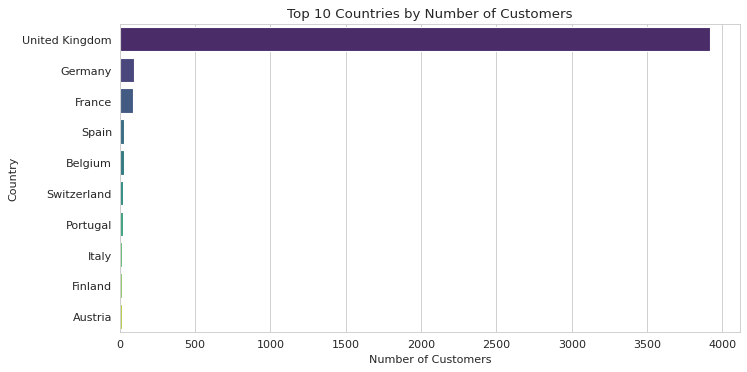

In [15]:
country_customers = df.groupby("Country")["CustomerID"].nunique().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=country_customers.values, y=country_customers.index, palette="viridis")
plt.title("Top 10 Countries by Number of Customers")
plt.xlabel("Number of Customers")
plt.ylabel("Country")
plt.show()

print(country_customers)

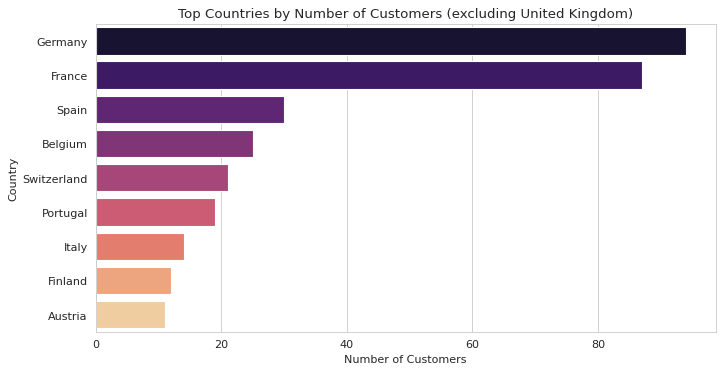

In [16]:
# Same idea but UK removed, so that the other countries are visible
country_no_uk = country_customers.drop("United Kingdom")

plt.figure(figsize=(10, 5))
sns.barplot(x=country_no_uk.values, y=country_no_uk.index, palette="magma")
plt.title("Top Countries by Number of Customers (excluding United Kingdom)")
plt.xlabel("Number of Customers")
plt.ylabel("Country")
plt.show()

### 4.2 Top 10 best-selling products (by quantity sold)

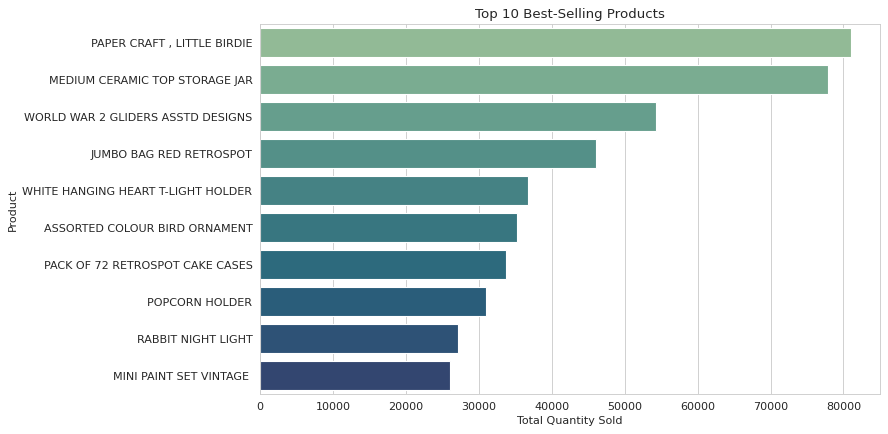

In [17]:
top_products = df.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_products.values, y=top_products.index, palette="crest")
plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.show()

### 4.3 Monthly sales trend

YearMonth
2010-12     570423.0
2011-01     568101.0
2011-02     446085.0
2011-03     594082.0
2011-04     468374.0
2011-05     677355.0
2011-06     660046.0
2011-07     598963.0
2011-08     644051.0
2011-09     950690.0
2011-10    1035642.0
2011-11    1156206.0
2011-12     517190.0
Name: TotalAmount, dtype: float64


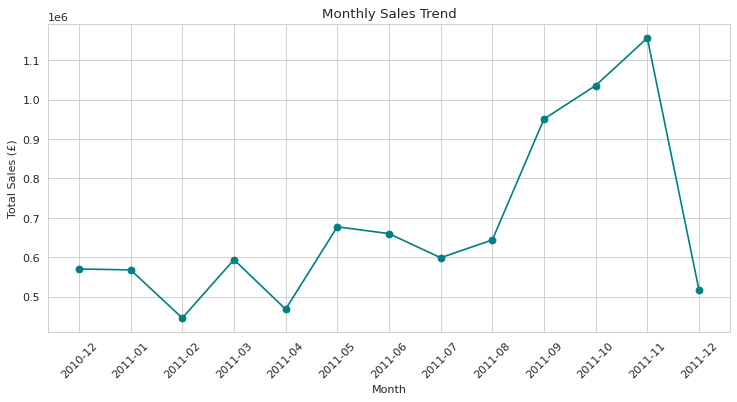

In [18]:
df["YearMonth"] = df["InvoiceDate"].dt.strftime("%Y-%m")       # example: 2011-03
monthly_sales = df.groupby("YearMonth")["TotalAmount"].sum()

plt.figure(figsize=(11, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o", color="teal")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (£)")
plt.xticks(rotation=45)
plt.show()

print(monthly_sales.round(0))

### 4.4 Revenue (TotalAmount) distribution and Quantity distribution

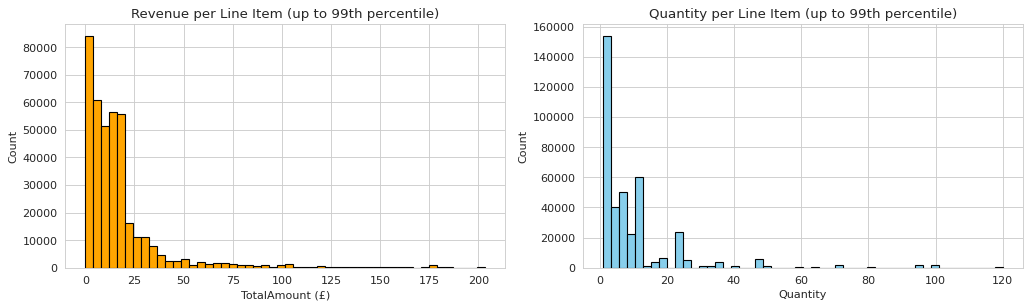

In [19]:
# We cut the graph at the 99th percentile, otherwise a few huge orders squash the whole graph
amount_limit = df["TotalAmount"].quantile(0.99)
qty_limit = df["Quantity"].quantile(0.99)

plt.figure(figsize=(13, 4))

plt.subplot(1, 2, 1)
plt.hist(df[df["TotalAmount"] <= amount_limit]["TotalAmount"], bins=50, color="orange", edgecolor="black")
plt.title("Revenue per Line Item (up to 99th percentile)")
plt.xlabel("TotalAmount (£)")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
plt.hist(df[df["Quantity"] <= qty_limit]["Quantity"], bins=50, color="skyblue", edgecolor="black")
plt.title("Quantity per Line Item (up to 99th percentile)")
plt.xlabel("Quantity")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

### 4.5 Extra graphs: busiest hours of the day and customer revenue

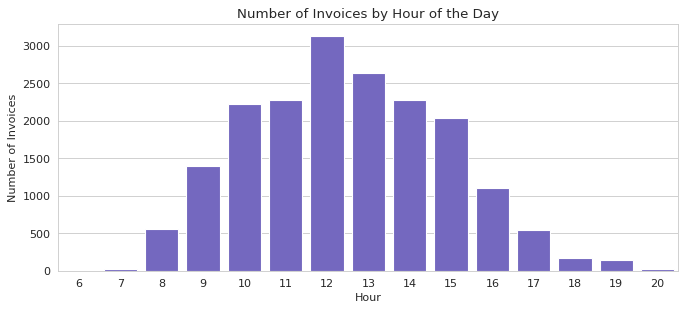

In [20]:
df["Hour"] = df["InvoiceDate"].dt.hour
orders_by_hour = df.groupby("Hour")["InvoiceNo"].nunique()

plt.figure(figsize=(10, 4))
sns.barplot(x=orders_by_hour.index, y=orders_by_hour.values, color="slateblue")
plt.title("Number of Invoices by Hour of the Day")
plt.xlabel("Hour")
plt.ylabel("Number of Invoices")
plt.show()

In [21]:
# How much of the revenue comes from the top 10 customers?
customer_revenue = df.groupby("CustomerID")["TotalAmount"].sum().sort_values(ascending=False)
top10_share = customer_revenue.head(10).sum() / customer_revenue.sum() * 100
top20pct_share = customer_revenue.head(int(len(customer_revenue) * 0.2)).sum() / customer_revenue.sum() * 100

print("Total revenue (£):", round(customer_revenue.sum(), 2))
print("Top 10 customers give", round(top10_share, 2), "% of the revenue")
print("Top 20% of customers give", round(top20pct_share, 2), "% of the revenue")

Total revenue (£): 8887208.89
Top 10 customers give 17.3 % of the revenue
Top 20% of customers give 74.66 % of the revenue


In [22]:
uk_share = (df[df["Country"] == "United Kingdom"]["TotalAmount"].sum() / df["TotalAmount"].sum()) * 100
print("United Kingdom share of total revenue:", round(uk_share, 2), "%")
print("Best month by sales:", monthly_sales.idxmax())
print("Busiest hour (by invoices):", orders_by_hour.idxmax())

United Kingdom share of total revenue: 81.97 %
Best month by sales: 2011-11
Busiest hour (by invoices): 12



### Observations from EDA
- **Country:** The business is overwhelmingly UK-based: 3,920 of the 4,338 customers are from the United Kingdom, followed by Germany (94) and France (87). The UK also gives about 82% of total revenue.
- **Monthly trend:** Sales rise strongly from September to November 2011 (November is the highest month, about £1.16 million), which looks like Christmas-season buying. The December 2011 bar is low only because the data stops on 9 December, not because sales fell.
- **Distributions:** Both revenue per line and quantity per line are strongly right-skewed: most purchases are small and a few are very large. (Because of this, a few huge orders can dominate "best-seller" lists, so treat the top-product graph with some care.)
- **Customer concentration:** The top 20% of customers produce about 75% of the revenue, and the top 10 customers alone produce about 17%. This is why customer segmentation is valuable: a small group of customers matters most.
- **Time of day:** The busiest hour for invoices is 12 (noon).


## Step 5: RFM Analysis

RFM is a very popular marketing method that describes every customer with three numbers:

- **Recency (R)** – how many days ago the customer last purchased. **Lower is better** (recent customers are more likely to buy again).
- **Frequency (F)** – how many *unique invoices* (separate orders) the customer made. **Higher is better.**
- **Monetary (M)** – total money the customer spent. **Higher is better.**

**Reference date:** the latest date in the data **plus one day**. Recency = reference date − the customer's last purchase date (calendar dates only, ignoring time of day).

In [23]:
ref_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
print("Reference date:", ref_date)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (ref_date - x.max().normalize()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
).reset_index()

rfm.head(10)

Reference date: 2011-12-10 00:00:00


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,3,7,4310.00
2,12348,76,4,1797.24
3,12349,19,1,1757.55
4,12350,311,1,334.40
5,12352,37,8,2506.04
6,12353,205,1,89.00
7,12354,233,1,1079.40
8,12355,215,1,459.40
9,12356,23,3,2811.43


In [24]:
print("RFM table shape:", rfm.shape)
print("Every row is one customer, so we have", len(rfm), "customers.")

RFM table shape: (4338, 4)
Every row is one customer, so we have 4338 customers.


### 5.1 RFM summary statistics

In [25]:
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,93.059474,4.272015,2048.688081
std,100.012264,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.750000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


### 5.2 Distribution plots for Recency, Frequency and Monetary

Skewness (0 means symmetric; large positive means a long right tail):
Recency       1.25
Frequency    12.07
Monetary     19.34
dtype: float64


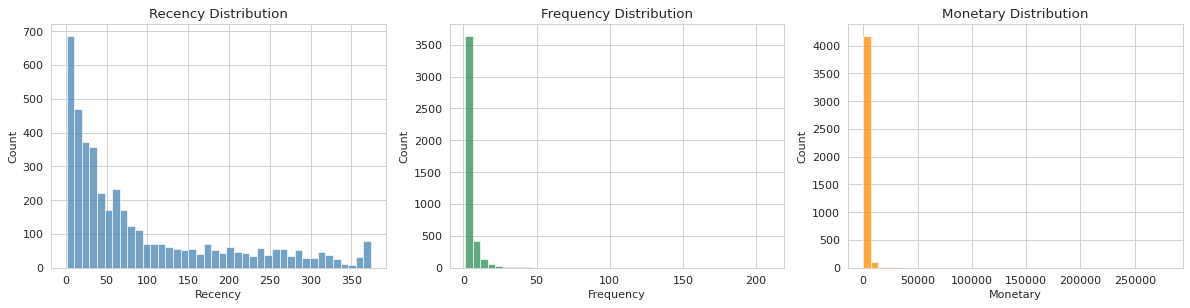

In [26]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(rfm["Recency"], bins=40, color="steelblue")
plt.title("Recency Distribution")

plt.subplot(1, 3, 2)
sns.histplot(rfm["Frequency"], bins=40, color="seagreen")
plt.title("Frequency Distribution")

plt.subplot(1, 3, 3)
sns.histplot(rfm["Monetary"], bins=40, color="darkorange")
plt.title("Monetary Distribution")

plt.tight_layout()
plt.show()

print("Skewness (0 means symmetric; large positive means a long right tail):")
print(rfm[["Recency", "Frequency", "Monetary"]].skew().round(2))

### 5.3 Correlation heatmap

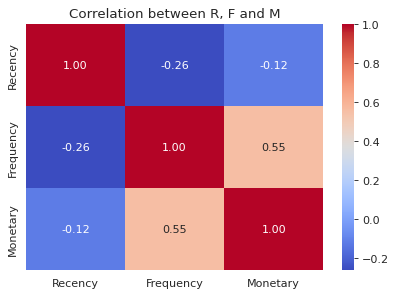

In [27]:
plt.figure(figsize=(6, 4))
sns.heatmap(rfm[["Recency", "Frequency", "Monetary"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between R, F and M")
plt.show()


### Observations from RFM
- We have **4,338 customers**. The typical (median) customer last bought 51 days before the reference date, placed 2 orders and spent about £669.
- The **mean** Monetary (about £2,049) is much bigger than the **median** (about £669), and the maximum is £280,206. A few giant customers pull the average up. Skewness values (Recency 1.25, Frequency 12.07, Monetary 19.34) confirm that Frequency and Monetary are extremely right-skewed. This is why we need the log transformation next.
- About **34% of customers bought only once** (Frequency = 1) — repeat purchasing is a major opportunity.
- **Correlation:** Frequency and Monetary are moderately positively correlated (0.55): customers who order more usually spend more. Recency has a weak negative correlation with Frequency (−0.26): frequent buyers tend to have bought more recently.


## Step 6: Feature Transformation and Scaling

**Why log transform?** Frequency and Monetary are *highly right-skewed*: most customers are small, a few are huge. K-Means and DBSCAN use distances, so these few giant values would dominate everything. `np.log1p(x)` computes log(1 + x), which squeezes large values and makes the data more balanced. (We use `log1p` rather than `log` so that a value of 0 would not cause an error.)

**Why scale?** Recency is in days (1–374), Frequency is a small count, and Monetary is in thousands of pounds. A feature with bigger numbers would unfairly control the distance calculation. `StandardScaler` changes every feature to mean = 0 and standard deviation = 1, so all three count equally.

We keep the **original** `rfm` values untouched, because we need real numbers (days, orders, pounds) when we explain the clusters to the business.

In [28]:
# Step 1: select the three features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]]

# Step 2: log transformation
rfm_log = np.log1p(rfm_features)

# Step 3: scaling
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

print("Scaled data shape:", rfm_scaled.shape)
print("Mean of each scaled column (should be about 0):", rfm_scaled.mean(axis=0).round(3))
print("Std of each scaled column (should be 1):", rfm_scaled.std(axis=0).round(3))

Scaled data shape: (4338, 3)
Mean of each scaled column (should be about 0): [ 0. -0. -0.]
Std of each scaled column (should be 1): [1. 1. 1.]


In [29]:
# Compare skewness before and after the log transformation
print("Skewness BEFORE log:")
print(rfm_features.skew().round(2))
print()
print("Skewness AFTER log:")
print(rfm_log.skew().round(2))

Skewness BEFORE log:
Recency       1.25
Frequency    12.07
Monetary     19.34
dtype: float64

Skewness AFTER log:
Recency     -0.33
Frequency    1.21
Monetary     0.40
dtype: float64


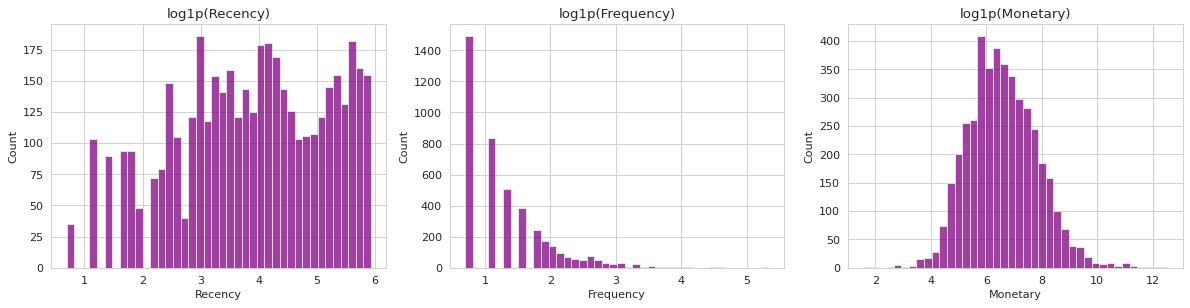

In [30]:
plt.figure(figsize=(15, 4))
for i, col in enumerate(["Recency", "Frequency", "Monetary"]):
    plt.subplot(1, 3, i + 1)
    sns.histplot(rfm_log[col], bins=40, color="purple")
    plt.title("log1p(" + col + ")")
plt.tight_layout()
plt.show()


**Result of the log transformation:** skewness dropped from 1.25 / 12.07 / 19.34 (Recency / Frequency / Monetary) to −0.33 / 1.21 / 0.40. The data is now much more balanced, so a few giant customers will not control the clustering. Frequency is still a little skewed because many customers have exactly 1 order, which is natural.


## Step 7: K-Means Clustering

**How K-Means works (simple version):**
1. Choose the number of clusters **K**.
2. Place K random centre points (centroids).
3. Give every customer to the nearest centroid.
4. Move each centroid to the average position of its customers.
5. Repeat steps 3 and 4 until nothing changes.

**How to choose K:**
- **Elbow Method (inertia):** inertia = total squared distance of customers from their own centroid. It always decreases as K grows. We look for the "elbow" where the improvement slows down.
- **Silhouette Score:** ranges from −1 to +1. Higher means customers are close to their own cluster and far from other clusters.

We try K = 2 to 10.

In [31]:
k_values = range(2, 11)
inertia_list = []
silhouette_list = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(rfm_scaled)
    inertia_list.append(model.inertia_)
    silhouette_list.append(silhouette_score(rfm_scaled, labels))

k_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": np.round(inertia_list, 1),
    "Silhouette_Score": np.round(silhouette_list, 4)
})
k_results

,K,Inertia,Silhouette_Score
0,2,6476.5,0.4325
1,3,4858.2,0.3363
2,4,3925.4,0.3329
3,5,3269.3,0.3181
4,6,2841.4,0.3129
5,7,2533.0,0.3103
6,8,2325.1,0.3021
7,9,2156.0,0.2960
8,10,1989.4,0.2771


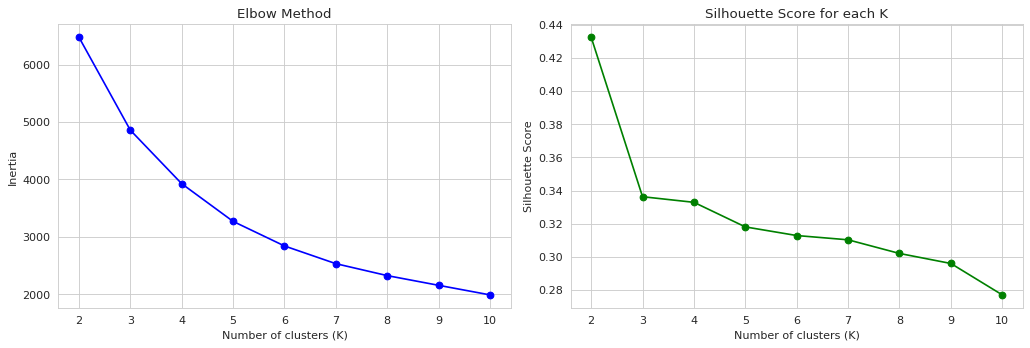

In [32]:
plt.figure(figsize=(13, 4.5))

plt.subplot(1, 2, 1)
plt.plot(list(k_values), inertia_list, marker="o", color="blue")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
plt.plot(list(k_values), silhouette_list, marker="o", color="green")
plt.title("Silhouette Score for each K")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")

plt.tight_layout()
plt.show()


### How we choose K (using the actual results above)

| K | Inertia | Silhouette |
|---|---|---|
| 2 | 6476.5 | 0.4325 |
| 3 | 4858.2 | 0.3363 |
| 4 | 3925.4 | 0.3329 |
| 5 | 3269.3 | 0.3181 |
| 10 | 1989.4 | 0.2771 |

- **Elbow graph:** inertia keeps falling smoothly; there is no sharp elbow. The biggest improvements happen when moving from K=2 to K=3 and K=3 to K=4; after that the curve flattens gradually.
- **Silhouette graph:** the highest score is at K=2 (0.4325), but K=2 only splits customers into "active" and "inactive", which is too simple for marketing. K=3 (0.3363) and K=4 (0.3329) are almost identical in score (difference about 0.003). After K=4 the score keeps decreasing.
- **Business view:** K=4 gives four groups that each need a *different* marketing action (top customers, regular customers who are cooling down, recent small customers, and lapsed customers), while still keeping a silhouette score almost equal to K=3. More than 4 clusters would be harder to explain and act on.

**Decision: final K = 4.** This is a judgement that balances the scores with business usefulness. K=3 would also be a defensible answer; you should be ready to explain that K=2 has the best score but is too coarse.


In [33]:
final_k = 4

kmeans = KMeans(n_clusters=final_k, random_state=42, n_init=10)
rfm["KMeans_Cluster"] = kmeans.fit_predict(rfm_scaled)

# K-Means gives random cluster numbers. To make the numbering meaningful and repeatable,
# we renumber the clusters so that Cluster 0 has the HIGHEST average Monetary, Cluster 1 the next, and so on.
order = rfm.groupby("KMeans_Cluster")["Monetary"].mean().sort_values(ascending=False).index
new_numbers = {}
for new_number, old_number in enumerate(order):
    new_numbers[old_number] = new_number
rfm["KMeans_Cluster"] = rfm["KMeans_Cluster"].map(new_numbers)

kmeans_silhouette = silhouette_score(rfm_scaled, rfm["KMeans_Cluster"])
print("Final K =", final_k)
print("Silhouette Score of final K-Means model:", round(kmeans_silhouette, 4))
print()
print("Number of customers in each K-Means cluster:")
print(rfm["KMeans_Cluster"].value_counts().sort_index())

Final K = 4
Silhouette Score of final K-Means model: 0.3329

Number of customers in each K-Means cluster:
KMeans_Cluster
0     718
1    1174
2     897
3    1549
Name: count, dtype: int64


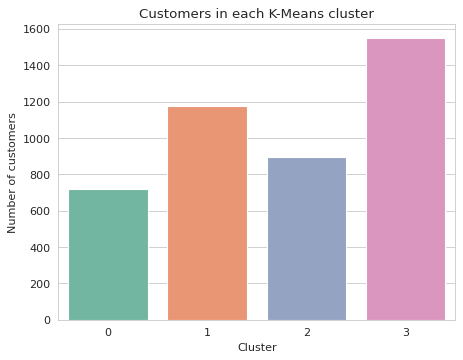

In [34]:
sns.countplot(x="KMeans_Cluster", data=rfm, palette="Set2")
plt.title("Customers in each K-Means cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of customers")
plt.show()

## Step 8: PCA (Principal Component Analysis)

Our data has 3 features (R, F, M), but a screen has only 2 dimensions. **PCA** creates new axes called *principal components*. PC1 is the direction with the **most spread (information)**, PC2 the next best direction that is at right angles to PC1.

We use PCA **only to draw a 2D picture**. The clustering itself was done on the 3 scaled RFM features, **not** on the PCA values.

In [35]:
pca = PCA(n_components=2, random_state=42)
pca_data = pca.fit_transform(rfm_scaled)

rfm["PCA1"] = pca_data[:, 0]
rfm["PCA2"] = pca_data[:, 1]

explained = pca.explained_variance_ratio_
print("Explained variance ratio of PC1:", round(explained[0], 4), "(", round(explained[0] * 100, 2), "% )")
print("Explained variance ratio of PC2:", round(explained[1], 4), "(", round(explained[1] * 100, 2), "% )")
print("Cumulative explained variance  :", round(explained.sum(), 4), "(", round(explained.sum() * 100, 2), "% )")
print()
print("Information lost by using only 2 components:", round((1 - explained.sum()) * 100, 2), "%")

Explained variance ratio of PC1: 0.7512 ( 75.12 % )
Explained variance ratio of PC2: 0.1874 ( 18.74 % )
Cumulative explained variance  : 0.9386 ( 93.86 % )

Information lost by using only 2 components: 6.14 %


In [36]:
# Which original features build each component? (called loadings)
loadings = pd.DataFrame(pca.components_, columns=["Recency", "Frequency", "Monetary"], index=["PC1", "PC2"])
loadings.round(3)

,Recency,Frequency,Monetary
PC1,-0.512,0.618,0.597
PC2,0.850,0.262,0.458


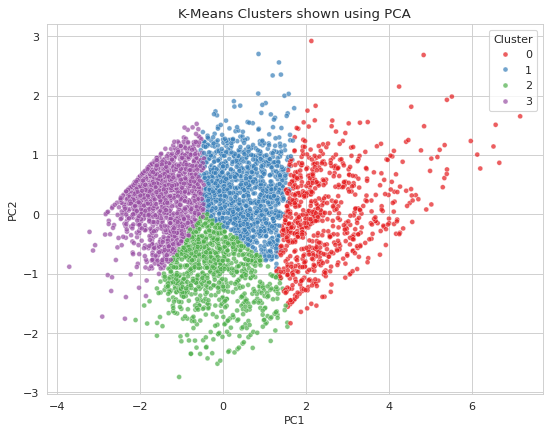

In [37]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x="PCA1", y="PCA2", hue="KMeans_Cluster", data=rfm, palette="Set1", s=20, alpha=0.7)
plt.title("K-Means Clusters shown using PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.show()


### Explanation of the PCA results
- **PC1 explains 75.12%** and **PC2 explains 18.74%** of the variance. Together, **two components keep 93.86%** of the information in the 3 RFM features, and only 6.14% is lost. So the 2D picture is a faithful summary.
- **Loadings:** PC1 is made mainly of Frequency (+0.62) and Monetary (+0.60) with Recency negative (−0.51). So PC1 can be read as a "customer value / engagement" axis: moving right means more orders, more spending and more recent purchases. PC2 is mainly Recency (+0.85).
- **Reading the graph:** the clusters appear as neighbouring slices from left to right. The left side (Cluster 3, purple) holds inactive low-value customers and the right side (Cluster 0, red) holds the high-value, frequent buyers. There are **no empty gaps** between clusters: the customers form one continuous cloud, and K-Means cuts it into four useful pieces. This is also why the Silhouette Score is moderate (about 0.33) and not close to 1.
- The few far-right red points are the biggest customers.


## Step 9: DBSCAN Clustering

**DBSCAN in simple words:** it finds *crowded (dense) areas* of customers and calls each crowded area a cluster. Customers that are alone in a sparse area are marked as **noise (label −1)**. Unlike K-Means, we do **not** have to tell DBSCAN the number of clusters, and it can find clusters of any shape.

**The two parameters:**
- **eps** – the radius of the circle drawn around a customer. Two customers are neighbours if their distance is less than eps.
- **min_samples** – the minimum number of customers (including itself) that must be inside the circle for a customer to be in a dense area ("core point").

**Choosing eps with a K-distance graph:** for every customer we find the distance to its k-th nearest neighbour (k = min_samples), sort these distances and plot them. The curve is flat for customers in dense areas and shoots up for isolated customers. A good eps is near the point where the curve starts rising sharply (the "knee").

Some percentiles of the k-distance:
50% : 0.166
90% : 0.369
95% : 0.477
99% : 0.864


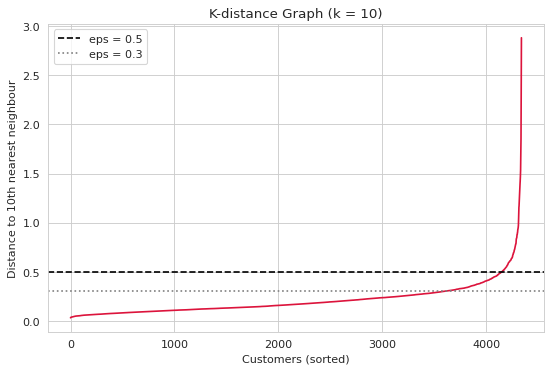

In [38]:
min_samples_value = 10

neighbors = NearestNeighbors(n_neighbors=min_samples_value)
neighbors.fit(rfm_scaled)
distances, indices = neighbors.kneighbors(rfm_scaled)

k_distances = np.sort(distances[:, min_samples_value - 1])    # distance to the 10th nearest point

plt.figure(figsize=(8, 5))
plt.plot(k_distances, color="crimson")
plt.axhline(y=0.5, color="black", linestyle="--", label="eps = 0.5")
plt.axhline(y=0.3, color="gray", linestyle=":", label="eps = 0.3")
plt.title("K-distance Graph (k = 10)")
plt.xlabel("Customers (sorted)")
plt.ylabel("Distance to 10th nearest neighbour")
plt.legend()
plt.show()

print("Some percentiles of the k-distance:")
print("50% :", round(np.percentile(k_distances, 50), 3))
print("90% :", round(np.percentile(k_distances, 90), 3))
print("95% :", round(np.percentile(k_distances, 95), 3))
print("99% :", round(np.percentile(k_distances, 99), 3))

### 9.1 Test different parameter combinations
We try a few reasonable values of eps and min_samples. For each, we count the clusters and noise points. The Silhouette Score is calculated **only on non-noise customers**, and only when there are at least 2 clusters.

In [39]:
test_rows = []

for eps_value in [0.2, 0.3, 0.4, 0.5, 0.6, 0.8]:
    for ms_value in [5, 10]:
        db_model = DBSCAN(eps=eps_value, min_samples=ms_value)
        db_labels = db_model.fit_predict(rfm_scaled)

        n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
        n_noise = list(db_labels).count(-1)

        if n_clusters >= 2:
            non_noise = db_labels != -1
            score = round(silhouette_score(rfm_scaled[non_noise], db_labels[non_noise]), 4)
        else:
            score = "not defined (less than 2 clusters)"

        sizes = pd.Series(db_labels[db_labels != -1]).value_counts().tolist()[:4]   # sizes of the biggest clusters

        test_rows.append([eps_value, ms_value, n_clusters, n_noise, sizes, score])

dbscan_tests = pd.DataFrame(test_rows, columns=["eps", "min_samples", "Clusters", "Noise_Points", "Biggest_Cluster_Sizes", "Silhouette_(non-noise only)"])
dbscan_tests

,eps,min_samples,Clusters,Noise_Points,Biggest_Cluster_Sizes,Silhouette_(non-noise only)
0,0.2,5,32,609,"[1417, 779, 420, 378]",-0.0239
1,0.2,10,11,1288,"[1362, 699, 376, 258]",0.089
2,0.3,5,6,244,"[1462, 1322, 820, 480]",0.0775
3,0.3,10,4,410,"[1426, 1246, 798, 458]",0.145
4,0.4,5,5,101,"[1928, 1474, 828, 4]",0.0752
5,0.4,10,3,160,"[1892, 1466, 820]",0.1738
6,0.5,5,2,62,"[2791, 1485]",0.2937
7,0.5,10,2,79,"[2780, 1479]",0.2946
8,0.6,5,2,36,"[4295, 7]",0.5724
9,0.6,10,1,52,[4286],not defined (less than 2 clusters)



### Choosing eps and min_samples
- **K-distance graph:** the curve is flat and low for most customers and rises sharply near **0.5** (about the 95th percentile of the distances). Values below this are the dense part of the data, values above it are isolated customers. So eps = 0.5 is a sensible starting point.
- **Parameter table:**
  - Small eps (0.2–0.3) splits the data into many tiny clusters and labels hundreds or even over a thousand customers as noise, which is too aggressive.
  - eps = 0.6 with min_samples = 5 shows a high Silhouette Score (0.57), but this is **misleading**: one giant cluster holds almost everyone and the other cluster has only a handful of customers (see `Biggest_Cluster_Sizes`). It is not a useful segmentation.
  - Large eps (0.6 with min_samples = 10, and 0.8) merges everything into 1 cluster, so no segmentation is possible.
  - **eps = 0.5 with min_samples = 10** gives 2 sizeable clusters, a small noise group (79 customers), and a Silhouette Score of about 0.29 on non-noise customers, so we choose this.


In [40]:
final_eps = 0.5
final_min_samples = 10

dbscan = DBSCAN(eps=final_eps, min_samples=final_min_samples)
rfm["DBSCAN_Cluster"] = dbscan.fit_predict(rfm_scaled)

print("Customers in each DBSCAN cluster (-1 means noise):")
print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

n_noise_final = (rfm["DBSCAN_Cluster"] == -1).sum()
n_clusters_final = len(set(rfm["DBSCAN_Cluster"])) - 1
print()
print("Number of clusters (without noise):", n_clusters_final)
print("Noise points:", n_noise_final, "(", round(n_noise_final / len(rfm) * 100, 2), "% of customers )")

# Silhouette Score only for non-noise customers
non_noise_mask = rfm["DBSCAN_Cluster"] != -1
dbscan_silhouette = silhouette_score(rfm_scaled[non_noise_mask], rfm.loc[non_noise_mask, "DBSCAN_Cluster"])
print()
print("DBSCAN Silhouette Score (calculated ONLY on non-noise customers):", round(dbscan_silhouette, 4))

Customers in each DBSCAN cluster (-1 means noise):
DBSCAN_Cluster
-1      79
 0    2780
 1    1479
Name: count, dtype: int64

Number of clusters (without noise): 2
Noise points: 79 ( 1.82 % of customers )

DBSCAN Silhouette Score (calculated ONLY on non-noise customers): 0.2946


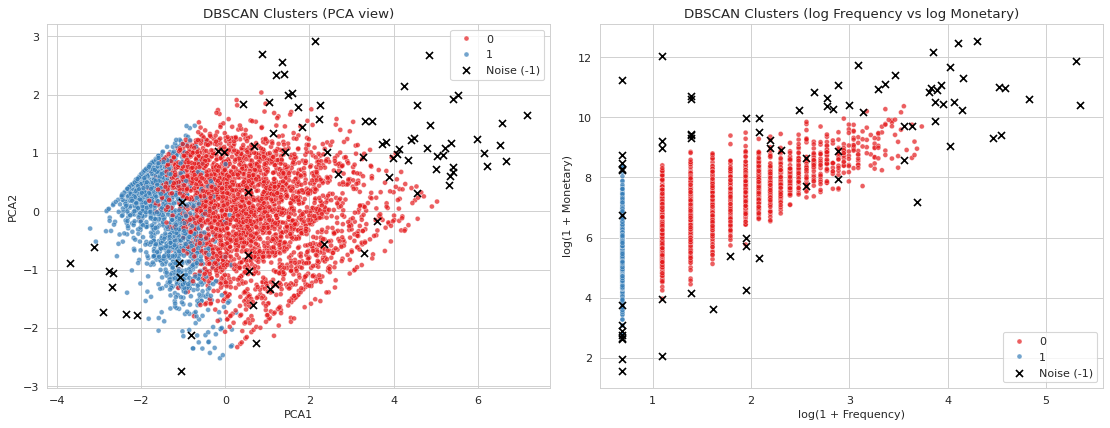

In [41]:
plt.figure(figsize=(14, 5.5))

# Left: PCA view (PCA is used only for drawing)
plt.subplot(1, 2, 1)
noise = rfm[rfm["DBSCAN_Cluster"] == -1]
normal = rfm[rfm["DBSCAN_Cluster"] != -1]
sns.scatterplot(x="PCA1", y="PCA2", hue="DBSCAN_Cluster", data=normal, palette="Set1", s=20, alpha=0.7)
plt.scatter(noise["PCA1"], noise["PCA2"], c="black", marker="x", s=40, label="Noise (-1)")
plt.title("DBSCAN Clusters (PCA view)")
plt.legend()

# Right: Frequency vs Monetary on the log scale
plt.subplot(1, 2, 2)
sns.scatterplot(x=np.log1p(normal["Frequency"]), y=np.log1p(normal["Monetary"]), hue=normal["DBSCAN_Cluster"], palette="Set1", s=20, alpha=0.7)
plt.scatter(np.log1p(noise["Frequency"]), np.log1p(noise["Monetary"]), c="black", marker="x", s=40, label="Noise (-1)")
plt.title("DBSCAN Clusters (log Frequency vs log Monetary)")
plt.xlabel("log(1 + Frequency)")
plt.ylabel("log(1 + Monetary)")
plt.legend()

plt.tight_layout()
plt.show()


### Explanation of the DBSCAN results
- DBSCAN found **2 clusters and 79 noise customers (about 1.8%)**.
- The data forms one connected, dense cloud, so DBSCAN cannot split it into many groups as K-Means does. It mainly separates the **customers with more than one order** (Cluster 0, 2,780 customers) from the **one-time customers** (Cluster 1, 1,479 customers). In the right-hand graph, Cluster 1 appears as the vertical line at Frequency = 1.
- The **noise points (black ×)** mostly lie at the far high-spending / high-frequency edge, plus some unusual single-order customers who spent a lot or very little. They are the "outlier" customers that do not belong to a dense group.
- The Silhouette Score (0.2946) was calculated **only on the 4,259 non-noise customers**, because noise points do not belong to any cluster.


## Step 10: t-SNE Visualization

**t-SNE** is another way to draw high-dimensional data in 2D. Unlike PCA (which keeps the overall straight-line structure), t-SNE focuses on keeping **neighbours together**: customers that are similar in the original space are placed close to each other in the 2D picture.

Important points:
- t-SNE is for **visualization only**. Distances *between* far-away groups and the size of groups in a t-SNE picture should not be over-interpreted.
- It is **not** used as the input for clustering. Both K-Means and DBSCAN were run on the scaled RFM data.
- It can take a minute to run.

In [42]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42, init="pca", learning_rate="auto")
tsne_data = tsne.fit_transform(rfm_scaled)

rfm["TSNE1"] = tsne_data[:, 0]
rfm["TSNE2"] = tsne_data[:, 1]
print("t-SNE finished. Shape:", tsne_data.shape)

t-SNE finished. Shape: (4338, 2)


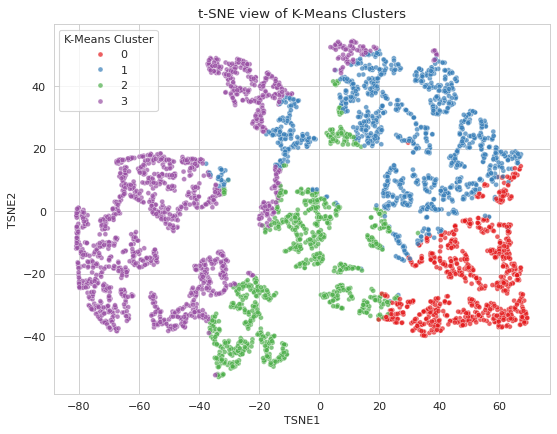

In [43]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x="TSNE1", y="TSNE2", hue="KMeans_Cluster", data=rfm, palette="Set1", s=20, alpha=0.7)
plt.title("t-SNE view of K-Means Clusters")
plt.legend(title="K-Means Cluster")
plt.show()

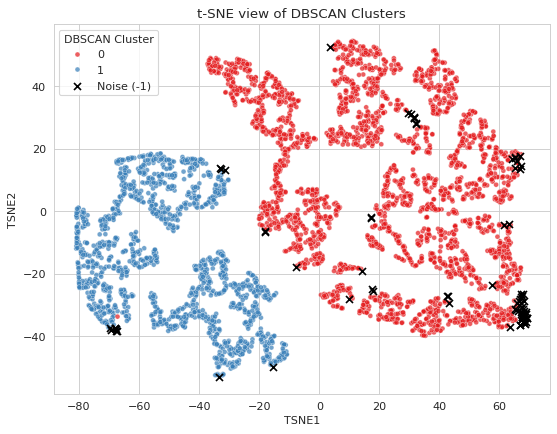

In [44]:
plt.figure(figsize=(8, 6))
noise = rfm[rfm["DBSCAN_Cluster"] == -1]
normal = rfm[rfm["DBSCAN_Cluster"] != -1]
sns.scatterplot(x="TSNE1", y="TSNE2", hue="DBSCAN_Cluster", data=normal, palette="Set1", s=20, alpha=0.7)
plt.scatter(noise["TSNE1"], noise["TSNE2"], c="black", marker="x", s=40, label="Noise (-1)")
plt.title("t-SNE view of DBSCAN Clusters")
plt.legend(title="DBSCAN Cluster")
plt.show()


### Explanation of the t-SNE results
- t-SNE places similar customers close together. The K-Means t-SNE graph shows that customers with the same K-Means label mostly sit in the same regions: Cluster 3 (lapsed, purple) mostly on the left, Cluster 0 (Champions, red) mostly towards the right and lower right, and Clusters 1 and 2 in between. This supports the K-Means clusters being meaningful, although some neighbouring clusters touch each other (as expected, because the data is continuous).
- In the DBSCAN t-SNE graph the two DBSCAN clusters occupy clearly different areas (one-time customers on the left, repeat customers on the right), and the noise points sit mainly along the right edge, where the highest-value customers are.
- The small "islands" in the picture are partly an effect of t-SNE (and of the fact that Frequency has whole-number values). **Do not** read too much into the distances between islands or the exact shapes. t-SNE is a picture, not a clustering method.


## Step 11: Cluster Profiling

Now we go back to the **original (unscaled) RFM values** and describe each cluster in real numbers: days, orders and pounds.

### 11.1 K-Means cluster profile

In [45]:
total_customers = len(rfm)
total_revenue = rfm["Monetary"].sum()

kmeans_profile = rfm.groupby("KMeans_Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Median_Recency=("Recency", "median"),
    Avg_Frequency=("Frequency", "mean"),
    Median_Frequency=("Frequency", "median"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median"),
    Total_Revenue=("Monetary", "sum")
).reset_index()

kmeans_profile["Pct_of_Customers"] = kmeans_profile["Customers"] / total_customers * 100
kmeans_profile["Pct_of_Revenue"] = kmeans_profile["Total_Revenue"] / total_revenue * 100
kmeans_profile = kmeans_profile.round(2)
kmeans_profile

,KMeans_Cluster,Customers,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary,Total_Revenue,Pct_of_Customers,Pct_of_Revenue
0,0,718,12.21,9.0,13.64,10.0,8011.89,3687.77,5752537.18,16.55,64.73
1,1,1174,65.29,52.0,4.19,4.0,1822.98,1355.04,2140183.49,27.06,24.08
2,2,897,22.79,20.0,1.92,2.0,486.06,414.20,435999.12,20.68,4.91
3,3,1549,192.27,187.0,1.35,1.0,360.55,303.16,558489.10,35.71,6.28


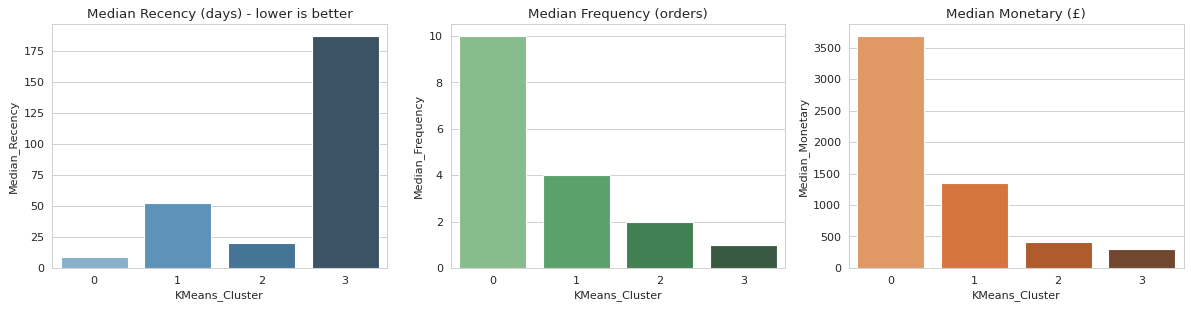

In [46]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.barplot(x="KMeans_Cluster", y="Median_Recency", data=kmeans_profile, palette="Blues_d")
plt.title("Median Recency (days) - lower is better")

plt.subplot(1, 3, 2)
sns.barplot(x="KMeans_Cluster", y="Median_Frequency", data=kmeans_profile, palette="Greens_d")
plt.title("Median Frequency (orders)")

plt.subplot(1, 3, 3)
sns.barplot(x="KMeans_Cluster", y="Median_Monetary", data=kmeans_profile, palette="Oranges_d")
plt.title("Median Monetary (£)")

plt.tight_layout()
plt.show()

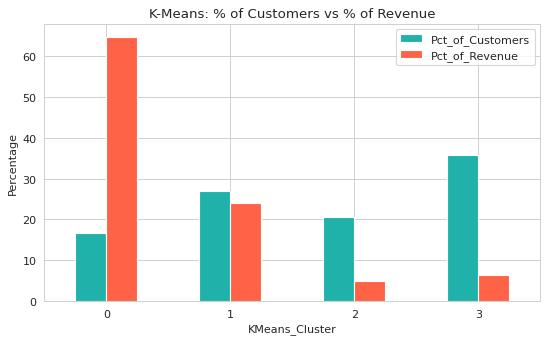

In [47]:
# Customers share vs revenue share
share = kmeans_profile[["KMeans_Cluster", "Pct_of_Customers", "Pct_of_Revenue"]].set_index("KMeans_Cluster")
share.plot(kind="bar", figsize=(8, 4.5), color=["lightseagreen", "tomato"])
plt.title("K-Means: % of Customers vs % of Revenue")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.show()


### What the K-Means profile means for the business
- **Cluster 0 (718 customers, 16.55%)** generates **64.73% of total revenue**. They ordered most recently (median 9 days), most often (median 10 orders) and spent the most (median £3,688).
- **Cluster 1 (1,174 customers, 27.06%)** is a solid middle group (median 4 orders, £1,355) producing 24.08% of revenue, but their median Recency is 52 days, so they are slowly becoming inactive.
- **Cluster 2 (897 customers, 20.68%)** bought recently (median 20 days) but only about twice and with small spending: 4.91% of revenue.
- **Cluster 3 (1,549 customers, 35.71%)** is the largest group but contributes only 6.28% of revenue; the median last order was 187 days ago with 1 order.
- **Key message:** about 17% of customers bring about 65% of revenue, and the large group at the bottom brings very little. Marketing money should therefore be spread unevenly: protect Cluster 0, nurture Clusters 1 and 2, and spend little on Cluster 3.
- Notice that the mean is often much larger than the median (e.g. Cluster 0: average Monetary £8,012 vs median £3,688). A few very large customers pull the average up, so the **median** is the more reliable "typical customer" number.


### 11.2 DBSCAN cluster profile (noise is shown as its own row, label -1)

In [48]:
dbscan_profile = rfm.groupby("DBSCAN_Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Median_Recency=("Recency", "median"),
    Avg_Frequency=("Frequency", "mean"),
    Median_Frequency=("Frequency", "median"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Monetary=("Monetary", "median"),
    Total_Revenue=("Monetary", "sum")
).reset_index()

dbscan_profile["Pct_of_Customers"] = dbscan_profile["Customers"] / total_customers * 100
dbscan_profile["Pct_of_Revenue"] = dbscan_profile["Total_Revenue"] / total_revenue * 100
dbscan_profile = dbscan_profile.round(2)
dbscan_profile

,DBSCAN_Cluster,Customers,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary,Total_Revenue,Pct_of_Customers,Pct_of_Revenue
0,-1,79,58.04,12.0,28.62,12.0,36425.69,13375.87,2877629.73,1.82,32.38
1,0,2780,59.69,31.0,5.32,4.0,1975.79,1127.28,5492703.64,64.08,61.80
2,1,1479,157.65,134.0,1.00,1.0,349.48,256.11,516875.52,34.09,5.82



### What the DBSCAN profile means for the business
- **DBSCAN Cluster 0** (2,780 customers, 64.08%) holds the repeat customers (median 4 orders, median £1,127) and produces 61.80% of revenue.
- **DBSCAN Cluster 1** (1,479 customers, 34.09%) contains only customers with exactly 1 order (median Recency 134 days, median £256) and produces only 5.82% of revenue.
- **Noise (label −1)** is just 79 customers (1.82%) but they generate **32.38% of the revenue** (average £36,426 per customer). These are extreme customers, such as very large buyers, so they should be managed individually, not treated as "bad data" to be ignored.


In [49]:
# A closer look at the noise customers: who are they?
noise_customers = rfm[rfm["DBSCAN_Cluster"] == -1]
print("Noise customers:", len(noise_customers))
print()
print(noise_customers[["Recency", "Frequency", "Monetary"]].describe().round(2))
print()
print("Top 5 noise customers by Monetary:")
print(noise_customers.sort_values("Monetary", ascending=False)[["CustomerID", "Recency", "Frequency", "Monetary"]].head(5))

Noise customers: 79

       Recency  Frequency   Monetary
count    79.00      79.00      79.00
mean     58.04      28.62   36425.69
std      86.77      39.89   54727.54
min       1.00       1.00       3.75
25%       4.00       3.00    2531.10
50%      12.00      12.00   13375.87
75%      80.50      45.50   47513.06
max     373.00     209.00  280206.02

Top 5 noise customers by Monetary:
      CustomerID  Recency  Frequency   Monetary
1689       14646        2         73  280206.02
4201       18102        1         60  259657.30
3728       17450        9         46  194390.79
3008       16446        1          2  168472.50
1879       14911        2        201  143711.17


## Step 12: Actionable Marketing Personas

A **persona** is a short, business-friendly name and description for a cluster. We decide the persona by reading the **actual RFM profile** of each cluster (Step 11), not by guessing.

Remember: low Recency = bought recently (good), high Frequency = many orders (good), high Monetary = big spender (good).

In [50]:
# Persona text for each K-Means cluster (written after studying the profile table in Step 11)
persona_rows = [
    {
        "Cluster": 0,
        "Persona": "Champions (High-Value Loyal Customers)",
        "Customer_Behaviour": "Bought very recently (median about 9 days ago), order often (median 10 orders) and spend the most (median about 3,688 pounds).",
        "Business_Importance": "Very high. Only about 17% of customers but about 65% of total revenue. Losing even a few of them would hurt sales badly.",
        "Marketing_Strategy": "VIP treatment instead of heavy discounts: early access to new products, loyalty tiers and rewards, personal thank-you messages, bulk/wholesale pricing and referral bonuses.",
        "Suggested_Action": "Protect and grow. Assign priority support and set an alert if a Champion has not ordered for more than about 30 days so that someone contacts them personally."
    },
    {
        "Cluster": 1,
        "Persona": "Loyal Regulars (Cooling Down)",
        "Customer_Behaviour": "Repeat buyers (median 4 orders) with good spending (median about 1,355 pounds) but their last purchase was about 52 days ago, so they are slowly becoming less active.",
        "Business_Importance": "High. About 27% of customers and about 24% of revenue. They are the best source for creating new Champions.",
        "Marketing_Strategy": "Retention and upselling: reminder emails before the usual re-order time, loyalty points, product bundles, and 'spend a little more to reach the next reward level' offers.",
        "Suggested_Action": "Send a re-order reminder or small reward at around 30-45 days after their last order. If they pass about 90 days without ordering, move them to a win-back email."
    },
    {
        "Cluster": 2,
        "Persona": "Recent / Promising New Customers",
        "Customer_Behaviour": "Bought fairly recently (median about 20 days ago) but only about 2 orders and low spending (median about 414 pounds).",
        "Business_Importance": "Medium. About 21% of customers but only about 5% of revenue today. Their value depends on whether they come back again.",
        "Marketing_Strategy": "Onboarding: welcome email series, recommendations of popular products, a small incentive for the next order, and free-delivery or bundle offers to increase basket size.",
        "Suggested_Action": "Aim to get a third order within the next 30 days with a time-limited offer. Customers who repeat can later move into the Loyal Regulars group."
    },
    {
        "Cluster": 3,
        "Persona": "At-Risk / Lapsed Low-Value Customers",
        "Customer_Behaviour": "Last purchase was long ago (median about 187 days), usually just 1 order, and the lowest spending (median about 303 pounds).",
        "Business_Importance": "Low revenue per customer (about 36% of customers but only about 6% of revenue), but they are the biggest group, so a cheap win-back campaign can still pay off.",
        "Marketing_Strategy": "Low-cost reactivation: one or two win-back emails with a limited-time offer or a 'we miss you' message, and a short survey asking why they stopped buying.",
        "Suggested_Action": "Do not spend much money on them. Try a maximum of two win-back messages and then stop contacting those who do not respond, to save marketing cost."
    }
]

persona_kmeans = pd.DataFrame(persona_rows)

# Add the real numbers from the K-Means profile table
numbers = kmeans_profile[["KMeans_Cluster", "Customers", "Pct_of_Customers", "Pct_of_Revenue",
                          "Median_Recency", "Median_Frequency", "Median_Monetary",
                          "Avg_Recency", "Avg_Frequency", "Avg_Monetary"]]
persona_kmeans = persona_kmeans.merge(numbers, left_on="Cluster", right_on="KMeans_Cluster").drop(columns="KMeans_Cluster")
persona_kmeans.insert(0, "Algorithm", "K-Means")

persona_kmeans[["Cluster", "Persona", "Customers", "Pct_of_Customers", "Pct_of_Revenue",
                "Median_Recency", "Median_Frequency", "Median_Monetary"]]

,Cluster,Persona,Customers,Pct_of_Customers,Pct_of_Revenue,Median_Recency,Median_Frequency,Median_Monetary
0,0,Champions (High-Value Loyal Customers),718,16.55,64.73,9.0,10.0,3687.77
1,1,Loyal Regulars (Cooling Down),1174,27.06,24.08,52.0,4.0,1355.04
2,2,Recent / Promising New Customers,897,20.68,4.91,20.0,2.0,414.20
3,3,At-Risk / Lapsed Low-Value Customers,1549,35.71,6.28,187.0,1.0,303.16


In [51]:
# Print each persona in a readable way (useful for the presentation)
for i in range(len(persona_kmeans)):
    row = persona_kmeans.iloc[i]
    print("=" * 80)
    print("K-Means Cluster", row["Cluster"], "->", row["Persona"])
    print("Customers:", row["Customers"], "(", row["Pct_of_Customers"], "% of customers,", row["Pct_of_Revenue"], "% of revenue )")
    print("Median R / F / M :", row["Median_Recency"], "days /", row["Median_Frequency"], "orders / £", row["Median_Monetary"])
    print("Average R / F / M:", row["Avg_Recency"], "days /", row["Avg_Frequency"], "orders / £", row["Avg_Monetary"])
    print("Behaviour  :", row["Customer_Behaviour"])
    print("Importance :", row["Business_Importance"])
    print("Strategy   :", row["Marketing_Strategy"])
    print("Action     :", row["Suggested_Action"])

K-Means Cluster 0 -> Champions (High-Value Loyal Customers)
Customers: 718 ( 16.55 % of customers, 64.73 % of revenue )
Median R / F / M : 9.0 days / 10.0 orders / £ 3687.77
Average R / F / M: 12.21 days / 13.64 orders / £ 8011.89
Behaviour  : Bought very recently (median about 9 days ago), order often (median 10 orders) and spend the most (median about 3,688 pounds).
Importance : Very high. Only about 17% of customers but about 65% of total revenue. Losing even a few of them would hurt sales badly.
Strategy   : VIP treatment instead of heavy discounts: early access to new products, loyalty tiers and rewards, personal thank-you messages, bulk/wholesale pricing and referral bonuses.
Action     : Protect and grow. Assign priority support and set an alert if a Champion has not ordered for more than about 30 days so that someone contacts them personally.
K-Means Cluster 1 -> Loyal Regulars (Cooling Down)
Customers: 1174 ( 27.06 % of customers, 24.08 % of revenue )
Median R / F / M : 52.0 d


### DBSCAN clusters and noise (explained separately)
DBSCAN found only two broad clusters, so the personas are less detailed than K-Means. We describe the two clusters, but we treat **noise (−1) as a special group of outliers that needs manual review, not as a normal marketing persona.**


In [52]:
# DBSCAN clusters are described separately. Noise (-1) is NOT given a normal marketing persona.
dbscan_rows = [
    {
        "Cluster": 0,
        "Persona": "Broad Active Customer Base (DBSCAN interpretation)",
        "Customer_Behaviour": "A large mixed group that bought repeatedly (median 4 orders) with a median last purchase about 31 days ago. It contains most K-Means Champions and Loyal Regulars, many Recent customers and also some lapsed customers (see the cross-table in Step 13).",
        "Business_Importance": "Very high: about 64% of customers and about 62% of revenue, but too broad to target with one message.",
        "Marketing_Strategy": "Treat as the core customer base: regular newsletters, loyalty programme and cross-selling. For specific campaigns use the K-Means personas inside this group.",
        "Suggested_Action": "Use K-Means personas for targeting; use this DBSCAN cluster only to see the main body of active customers."
    },
    {
        "Cluster": 1,
        "Persona": "One-Time / Inactive Customers (DBSCAN interpretation)",
        "Customer_Behaviour": "Every customer in this group has exactly 1 order, with a median last purchase about 134 days ago and low spending (median about 256 pounds).",
        "Business_Importance": "Low revenue (about 6%) but about 34% of customers. These are customers who have not yet been converted into repeat buyers.",
        "Marketing_Strategy": "Second-purchase and win-back campaigns with a simple, low-cost offer.",
        "Suggested_Action": "Send a small 'second order' incentive and stop contacting non-responders after a couple of attempts."
    },
    {
        "Cluster": -1,
        "Persona": "NOISE / OUTLIERS - not a normal persona",
        "Customer_Behaviour": "Unusual customers that do not fit in any dense group. Most have extremely high spending and many orders (median about 12 orders and about 13,376 pounds), but some are odd cases such as a single very large order.",
        "Business_Importance": "Very high: only about 2% of customers but about 32% of revenue. They also include unusual cases that may be wholesale buyers or data oddities.",
        "Marketing_Strategy": "Do not use mass marketing. Review customer by customer: key-account management for genuine big buyers, and a data check for unusual one-off cases.",
        "Suggested_Action": "Have the sales team manually check the top noise customers (see Step 11). Genuine wholesale customers should get a dedicated account manager."
    }
]

persona_dbscan = pd.DataFrame(dbscan_rows)
numbers2 = dbscan_profile[["DBSCAN_Cluster", "Customers", "Pct_of_Customers", "Pct_of_Revenue",
                           "Median_Recency", "Median_Frequency", "Median_Monetary",
                           "Avg_Recency", "Avg_Frequency", "Avg_Monetary"]]
persona_dbscan = persona_dbscan.merge(numbers2, left_on="Cluster", right_on="DBSCAN_Cluster").drop(columns="DBSCAN_Cluster")
persona_dbscan.insert(0, "Algorithm", "DBSCAN")

persona_dbscan[["Cluster", "Persona", "Customers", "Pct_of_Customers", "Pct_of_Revenue",
                "Median_Recency", "Median_Frequency", "Median_Monetary"]]

,Cluster,Persona,Customers,Pct_of_Customers,Pct_of_Revenue,Median_Recency,Median_Frequency,Median_Monetary
0,0,Broad Active Customer Base (DBSCAN interpretat...,2780,64.08,61.80,31.0,4.0,1127.28
1,1,One-Time / Inactive Customers (DBSCAN interpre...,1479,34.09,5.82,134.0,1.0,256.11
2,-1,NOISE / OUTLIERS - not a normal persona,79,1.82,32.38,12.0,12.0,13375.87


In [53]:
# Combine both tables for the final export file
all_personas = pd.concat([persona_kmeans, persona_dbscan], ignore_index=True)
print("Total persona rows:", len(all_personas))

Total persona rows: 7


## Step 13: K-Means vs DBSCAN Comparison

First a quick look at how the two algorithms' clusters overlap (rows = K-Means clusters, columns = DBSCAN clusters, -1 = noise):

In [54]:
pd.crosstab(rfm["KMeans_Cluster"], rfm["DBSCAN_Cluster"])

DBSCAN_Cluster,-1,0,1
KMeans_Cluster,,,
0,45,673,0
1,15,1139,20
2,11,540,346
3,8,428,1113


In [55]:
kmeans_sizes = rfm["KMeans_Cluster"].value_counts().sort_index().to_dict()
dbscan_sizes = rfm["DBSCAN_Cluster"].value_counts().sort_index().to_dict()

comparison = pd.DataFrame({
    "Criteria": [
        "Number of clusters",
        "Customers in each cluster",
        "Noise points",
        "Silhouette Score",
        "How the Silhouette Score was calculated",
        "Ability to separate different customer groups",
        "Business interpretability",
        "Advantages",
        "Limitations"
    ],
    "K-Means": [
        str(final_k),
        str(kmeans_sizes),
        "0 (every customer is forced into a cluster)",
        round(kmeans_silhouette, 4),
        "On all " + str(len(rfm)) + " customers",
        "Splits the customers into 4 different value levels (from Champions to Lapsed customers)",
        "High - 4 clear personas, each with a different marketing action",
        "Simple and fast; every customer gets a group; we control the number of groups",
        "We must choose K; clusters are round slices of the data; extreme customers can pull the centres"
    ],
    "DBSCAN": [
        str(n_clusters_final),
        str(dbscan_sizes),
        str(n_noise_final) + " customers (" + str(round(n_noise_final / len(rfm) * 100, 2)) + "%)",
        round(dbscan_silhouette, 4),
        "Only on the " + str(len(rfm) - n_noise_final) + " non-noise customers (noise removed)",
        "Finds only 2 broad groups (active vs one-time); the data has no clear empty gaps between groups",
        "Medium - noise is very useful, but the 2 clusters are too broad for detailed marketing",
        "No need to choose the number of clusters; automatically finds outlier customers (noise)",
        "Very sensitive to eps and min_samples; struggles when density is similar everywhere; leaves some customers unlabelled"
    ]
})
comparison

,Criteria,K-Means,DBSCAN
0,Number of clusters,4,2
1,Customers in each cluster,"{0: 718, 1: 1174, 2: 897, 3: 1549}","{-1: 79, 0: 2780, 1: 1479}"
2,Noise points,0 (every customer is forced into a cluster),79 customers (1.82%)
3,Silhouette Score,0.3329,0.2946
4,How the Silhouette Score was calculated,On all 4338 customers,Only on the 4259 non-noise customers (noise re...
5,Ability to separate different customer groups,Splits the customers into 4 different value le...,Finds only 2 broad groups (active vs one-time)...
6,Business interpretability,"High - 4 clear personas, each with a different...","Medium - noise is very useful, but the 2 clust..."
7,Advantages,Simple and fast; every customer gets a group; ...,No need to choose the number of clusters; auto...
8,Limitations,We must choose K; clusters are round slices of...,Very sensitive to eps and min_samples; struggl...



### Which algorithm is more useful for this dataset?

- **Silhouette Scores must not be compared blindly.** K-Means (0.3329) was calculated on all 4,338 customers, while DBSCAN (0.2946) was calculated only on the 4,259 non-noise customers. Also, DBSCAN has just 2 clusters, which is a simpler task.
- **K-Means is more useful for marketing here.** RFM data forms one continuous cloud of customers with no empty gaps between groups, so DBSCAN can only separate "repeat customers" from "one-time customers". K-Means gives four groups with clearly different behaviour and different actions (Champions, Loyal Regulars, Recent customers, Lapsed customers).
- **DBSCAN is useful as a second tool.** It identified 79 outlier customers (1.8% of customers, 32.4% of revenue) that K-Means had put inside its normal clusters (45 of them in Cluster 0). This is something K-Means cannot do.
- **Best practice for this project:** use K-Means for the main customer personas and use DBSCAN to find the special outlier customers that need individual attention.


## Step 14: Business Insights and Recommendations

First, the answers calculated directly from the K-Means profile table:

In [56]:
best_revenue = kmeans_profile.loc[kmeans_profile["Total_Revenue"].idxmax()]
best_frequency = kmeans_profile.loc[kmeans_profile["Avg_Frequency"].idxmax()]
best_monetary = kmeans_profile.loc[kmeans_profile["Avg_Monetary"].idxmax()]
best_recency = kmeans_profile.loc[kmeans_profile["Avg_Recency"].idxmin()]

print("1. Highest revenue segment     : K-Means cluster", int(best_revenue["KMeans_Cluster"]),
      "- £", round(best_revenue["Total_Revenue"]), "(", best_revenue["Pct_of_Revenue"], "% of revenue )")
print("2. Most frequent buyers        : K-Means cluster", int(best_frequency["KMeans_Cluster"]),
      "- average", best_frequency["Avg_Frequency"], "orders")
print("3. Highest monetary value      : K-Means cluster", int(best_monetary["KMeans_Cluster"]),
      "- average £", best_monetary["Avg_Monetary"])
print("4. Lowest Recency (most recent): K-Means cluster", int(best_recency["KMeans_Cluster"]),
      "- average", best_recency["Avg_Recency"], "days since last order")

one_time = (rfm["Frequency"] == 1).sum()
print()
print("Customers with only 1 order:", one_time, "(", round(one_time / len(rfm) * 100, 1), "% of all customers )")
repeat_customers = rfm[rfm["Frequency"] > 1]
print("Revenue share of repeat customers (2+ orders):", round(repeat_customers["Monetary"].sum() / total_revenue * 100, 1), "%")

1. Highest revenue segment     : K-Means cluster 0 - £ 5752537 ( 64.73 % of revenue )
2. Most frequent buyers        : K-Means cluster 0 - average 13.64 orders
3. Highest monetary value      : K-Means cluster 0 - average £ 8011.89
4. Lowest Recency (most recent): K-Means cluster 0 - average 12.21 days since last order

Customers with only 1 order: 1493 ( 34.4 % of all customers )
Revenue share of repeat customers (2+ orders): 93.1 %



### Insights and recommendations (based on the actual results)

| Question | Answer from our results |
|---|---|
| Highest revenue segment? | K-Means Cluster 0, the Champions: about £5.75 million, 64.73% of revenue from 16.55% of customers |
| Purchases most frequently? | Cluster 0: average 13.64 orders (median 10) |
| Highest monetary value? | Cluster 0: average £8,012 (median £3,688) |
| Lowest Recency? | Cluster 0: average 12.21 days since the last order |
| Who should get loyalty rewards? | Cluster 0 (Champions), and the best customers of Cluster 1 to encourage them to move up |
| Who needs retention campaigns? | Cluster 1 (median 52 days since last order and slipping), plus an early-warning alert for any Champion who goes quiet for about 30+ days |
| Who needs reactivation? | Cluster 3 (median 187 days), using low-cost win-back messages only |

**How can the company increase repeat purchases?**
- About 34% of customers placed only one order. Cluster 2 (recent customers with about 2 orders) is the best group for a "second/third order" campaign because they have bought recently.
- Send re-order reminders to Cluster 1 around 30–45 days after the last order, before they drift away.
- Use bundles and free-delivery thresholds to increase order value.

**How can the company improve customer retention?**
- Build a loyalty / VIP programme for Cluster 0 because losing them is the biggest revenue risk (they bring about 65% of revenue).
- Review the 79 DBSCAN noise customers individually (they hold about 32% of revenue), for example with dedicated account managers.
- Track Recency each month; when a customer moves from one cluster to a less active one, trigger the matching campaign automatically.
- Keep marketing cost low for Cluster 3, and stop contacting customers who do not respond.

**Important limitations:** the data covers only about one year (Dec 2010 – 9 Dec 2011), mostly UK customers, and RFM ignores *what* customers buy. Our cleaning removes cancellation invoices but not the original sales they cancelled, so a few customers' Monetary values may be overstated. The recommendations are suggestions to be tested (for example with A/B tests), not guarantees.


## Step 15: Export Final CSV Files

We save five files in a folder called `outputs` (the code creates the folder if it does not exist). In Google Colab, open the left-side Files panel to download them.

In [57]:
# Create the output folder if it is not there
os.makedirs("outputs", exist_ok=True)

# 1. Customer-level file (RFM values + K-Means and DBSCAN labels)
customer_file = rfm[["CustomerID", "Recency", "Frequency", "Monetary", "KMeans_Cluster", "DBSCAN_Cluster"]].copy()
customer_file["KMeans_Persona"] = customer_file["KMeans_Cluster"].map(dict(zip(persona_kmeans["Cluster"], persona_kmeans["Persona"])))
customer_file["Is_DBSCAN_Noise"] = customer_file["DBSCAN_Cluster"] == -1
customer_file.to_csv("outputs/Ecommerce_Customer_Segmentation.csv", index=False)

# 2. K-Means cluster profile
kmeans_profile.to_csv("outputs/KMeans_Cluster_Profile.csv", index=False)

# 3. DBSCAN cluster profile
dbscan_profile.to_csv("outputs/DBSCAN_Cluster_Profile.csv", index=False)

# 4. Personas and marketing recommendations
all_personas.to_csv("outputs/Customer_Marketing_Personas.csv", index=False)

# 5. Model comparison
comparison.to_csv("outputs/Model_Comparison.csv", index=False)

# Check that all files were really saved
files = ["outputs/Ecommerce_Customer_Segmentation.csv", "outputs/KMeans_Cluster_Profile.csv", "outputs/DBSCAN_Cluster_Profile.csv",
         "outputs/Customer_Marketing_Personas.csv", "outputs/Model_Comparison.csv"]
for f in files:
    if os.path.exists(f):
        print("Saved:", f, "-", os.path.getsize(f), "bytes")
    else:
        print("NOT FOUND:", f)

Saved: outputs/Ecommerce_Customer_Segmentation.csv - 279655 bytes
Saved: outputs/KMeans_Cluster_Profile.csv - 413 bytes
Saved: outputs/DBSCAN_Cluster_Profile.csv - 354 bytes
Saved: outputs/Customer_Marketing_Personas.csv - 5000 bytes
Saved: outputs/Model_Comparison.csv - 1177 bytes


**What each file contains**

| File | Content |
|---|---|
| `Ecommerce_Customer_Segmentation.csv` | One row per customer: CustomerID, Recency, Frequency, Monetary, K-Means cluster, DBSCAN cluster, K-Means persona, noise flag |
| `KMeans_Cluster_Profile.csv` | Size, average/median R, F, M, total revenue and percentages for each K-Means cluster |
| `DBSCAN_Cluster_Profile.csv` | The same summary for DBSCAN clusters (including noise = -1) |
| `Customer_Marketing_Personas.csv` | Persona name, behaviour, RFM values, importance, strategy and action for every cluster |
| `Model_Comparison.csv` | K-Means vs DBSCAN comparison table |

In [58]:
# Quick check of the main output file
pd.read_csv("outputs/Ecommerce_Customer_Segmentation.csv").head()

,CustomerID,Recency,Frequency,Monetary,KMeans_Cluster,DBSCAN_Cluster,KMeans_Persona,Is_DBSCAN_Noise
0,12346,326,1,77183.60,1,-1,Loyal Regulars (Cooling Down),True
1,12347,3,7,4310.00,0,0,Champions (High-Value Loyal Customers),False
2,12348,76,4,1797.24,1,0,Loyal Regulars (Cooling Down),False
3,12349,19,1,1757.55,2,1,Recent / Promising New Customers,False
4,12350,311,1,334.40,3,1,At-Risk / Lapsed Low-Value Customers,False



## Step 16: Final Project Summary

**Project objective:** Segment e-commerce customers using RFM analysis, K-Means and DBSCAN clustering, visualise the segments using PCA and t-SNE, and convert the clusters into actionable marketing personas.

**Dataset information:** Online Retail dataset (UK online gift retailer): 541,909 rows and 8 columns in the original file, covering 1 Dec 2010 to 9 Dec 2011.

**Data cleaning summary:** Removed 5,268 duplicate rows, rows with missing CustomerID (the biggest loss), cancelled invoices (starting with "C") and rows with zero or negative Quantity or UnitPrice. Created `TotalAmount = Quantity × UnitPrice`. The cleaned data has **392,692 rows, 4,338 customers and 18,532 invoices**.

**RFM findings:** Median customer: 51 days since last order, 2 orders, about £669. Frequency and Monetary are strongly right-skewed, so we applied `log1p` and `StandardScaler`. About 34% of customers ordered only once. Top 20% of customers give about 75% of revenue.

**K-Means results:** Elbow and Silhouette (K = 2 to 10) were compared. K=2 has the best score (0.4325) but is too coarse; K=3 (0.3363) and K=4 (0.3329) are nearly equal, and **K = 4 was selected** for business interpretability. The four clusters have 718, 1,174, 897 and 1,549 customers.

**DBSCAN results:** With eps = 0.5 and min_samples = 10 (chosen using the K-distance graph and a parameter test table), DBSCAN found **2 clusters** (2,780 and 1,479 customers) and **79 noise customers**. Silhouette Score = 0.2946 on non-noise customers only.

**PCA:** PC1 = 75.12%, PC2 = 18.74%, cumulative = **93.86%** of the variance is kept in 2 dimensions.

**t-SNE findings:** The 2D t-SNE plots show that K-Means clusters occupy mostly separate regions, with lapsed customers on the left and high-value customers on the right, and that DBSCAN noise lies at the high-value edge. PCA and t-SNE were used only for visualization, never as clustering input.

**Final customer personas (K-Means):**

| Cluster | Persona | % customers | % revenue |
|---|---|---|---|
| 0 | Champions (High-Value Loyal) | 16.55% | 64.73% |
| 1 | Loyal Regulars (Cooling Down) | 27.06% | 24.08% |
| 2 | Recent / Promising New Customers | 20.68% | 4.91% |
| 3 | At-Risk / Lapsed Low-Value Customers | 35.71% | 6.28% |

DBSCAN noise (79 customers, 32.38% of revenue) is treated as a special outlier group for individual review.

**Important business recommendations:** Reward and protect Champions; send timely re-order reminders to Loyal Regulars; run onboarding and second-order offers for Recent customers; use only low-cost win-back messages for Lapsed customers; manage the 79 outlier customers individually.

**Conclusion:** RFM gives a simple and powerful description of customer behaviour. K-Means turned it into four clear and actionable segments, while DBSCAN added value by detecting a small group of extreme customers who bring a very large share of revenue. About 17% of customers generate about 65% of revenue, so focusing marketing on the right segment can increase revenue and retention.
